In [3]:
import pandas as pd
import numpy as np
import os
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf


In [4]:
os.path.join('data', 'knb-lter-bnz', '55_Hare_Data_2012.txt')

'data/knb-lter-bnz/55_Hare_Data_2012.txt'

In [6]:
obs = pd.read_csv(os.path.join('data','55_Hare_Data_2012.txt'))
obs.head()

,date,time,grid,trap,l_ear,r_ear,sex,age,weight,hindft,notes,b_key,session_id,study
0,11/26/1998,NaN,bonrip,1A,414D096A08,NaN,NaN,NaN,1370.0,160.0,NaN,917.0,51,Population
1,11/26/1998,NaN,bonrip,2C,414D320671,NaN,M,NaN,1430.0,NaN,NaN,936.0,51,Population
2,11/26/1998,NaN,bonrip,2D,414D103E3A,NaN,M,NaN,1430.0,NaN,NaN,921.0,51,Population
3,11/26/1998,NaN,bonrip,2E,414D262D43,NaN,NaN,NaN,1490.0,135.0,NaN,931.0,51,Population
4,11/26/1998,NaN,bonrip,3B,414D2B4B58,NaN,NaN,NaN,1710.0,150.0,NaN,933.0,51,Population


In [8]:
obs['date'] = pd.to_datetime(obs['date'])
obs['date'].dtype

dtype('<M8[ns]')

## Examine hare's age data

In [9]:
obs['age'].value_counts(dropna=False)

age
NaN          2111
A             564
J             267
a             183
j             128
1/2/2013       21
1/4/2013       21
3/4/2013       18
1              12
U              11
?              10
a 3/4 yr.       4
2 yrs.          3
u               3
A 3/4           2
1.5             2
3.5 yrs.        2
2.25 yrs        2
1 yr.           2
1 yr            2
a 1 yr.         2
A 1.5           1
2.5 yrs         1
3 yrs.          1
a 2 yrs.        1
J 3/4           1
2 yrs           1
A 1/2           1
a 1 yr          1
1.25            1
3.25 yrs.       1
Name: count, dtype: int64

document decisions
keep hares with j as juvenile, a = adult

In [ ]:
# Update age values to juvenile and adult for observations where 'a' and 'j' are included
obs.loc[obs['age'].str.contains('j', case=False, na=False), 'age'] = 'juvenile'
obs.loc[obs['age'].str.contains('a', case=False, na=False), 'age'] = 'adult'

obs_juv_adult = obs[obs['age'].isin(['juvenile', 'adult'])].copy()
print('Number of juvenile and adult hare observations (captures):', len(obs_juv_adult))

Number of juvenile and adult hare observations (captures): 1155


In [14]:
obs_juv_adult['year'] = obs_juv_adult['date'].dt.year

In [15]:
# Extract the year in which each obs happened
obs_juv_adult['year']

108     1999
109     1999
110     1999
111     1999
112     1999
        ... 
3355    2003
3359    2003
3360    2003
3367    2004
3369    2004
Name: year, Length: 1155, dtype: int32

In [18]:
# Count observations per year and age, then move age values into columns

obs_per_year = obs_juv_adult.groupby(['year', 'age']).size().unstack()
obs_per_year

age,adult,juvenile
year,,
1999,150.0,126.0
2000,159.0,67.0
2001,72.0,22.0
2002,3.0,NaN
2003,1.0,18.0
2004,NaN,8.0
2005,95.0,48.0
2006,101.0,15.0
2007,13.0,5.0


<Axes: title={'center': 'Juvenile and Adult snowshoe hare captures per year'}, xlabel='Year', ylabel='Number of captures'>

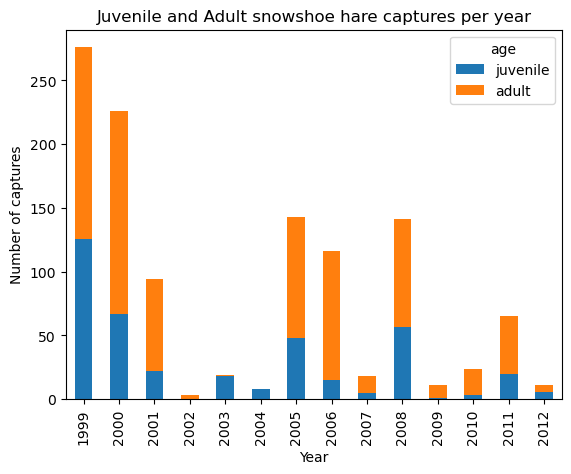

In [21]:
obs_per_year[['juvenile', 'adult']].plot(kind = "bar",
                                         stacked=True,
                                         title="Juvenile and Adult snowshoe hare captures per year",
                                         xlabel="Year",
                                         ylabel="Number of captures")